# Visualization of the metagenomic annotation

1. **Gain relative to KO** – for each sample, number of additional functions detected by each method compared with HUMAnN KO (`plot_df_all_methods.tsv`, from `build_detection_table.py`).
2. **Detection per function** – number of samples in which each function was detected, per method (heatmap).

Inputs:
- `plot_df_all_methods.tsv`
- `ko_relab_all_samples.tsv` (HUMAnN KO relative abundance, long format: KO, Function, Sample, Relab)
- `DBs_HITS_summary/<METHOD>_HITS_summary_scov.tsv` (UNIREF and DB1–DB6)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 1. Gain relative to KO

In [2]:
plot_df = pd.read_csv("/media/Kirk/thais/SialoCat/github/plot_df_all_methods.tsv", sep="\t")
print(plot_df["Method"].unique())

['KO' 'EC' 'DB1' 'DB2' 'DB3' 'DB4' 'DB5' 'DB6' 'UNIREF']


In [3]:
# Wide format: one row per sample, one column per method
wide = plot_df.pivot_table(
    index=["Sample"],
    columns="Method",
    values="Detected",
    fill_value=0
).reset_index()

# Methods compared with KO
methods = ["EC", "UNIREF", "DB1", "DB2", "DB3", "DB4", "DB5", "DB6"]

gain_list = []

for method in methods:
    temp = wide[["Sample", "KO", method]].copy()
    temp["Gain"] = temp[method] - temp["KO"]
    temp["Method"] = method
    gain_list.append(temp[["Sample", "Method", "Gain"]])

gain_df = pd.concat(gain_list, ignore_index=True)

print(gain_df.head())

Method       Sample Method  Gain
0       SRR31733811     EC  -1.0
1       SRR31733812     EC   0.0
2       SRR31733813     EC   5.0
3       SRR31733814     EC  -1.0
4       SRR31733815     EC  -1.0


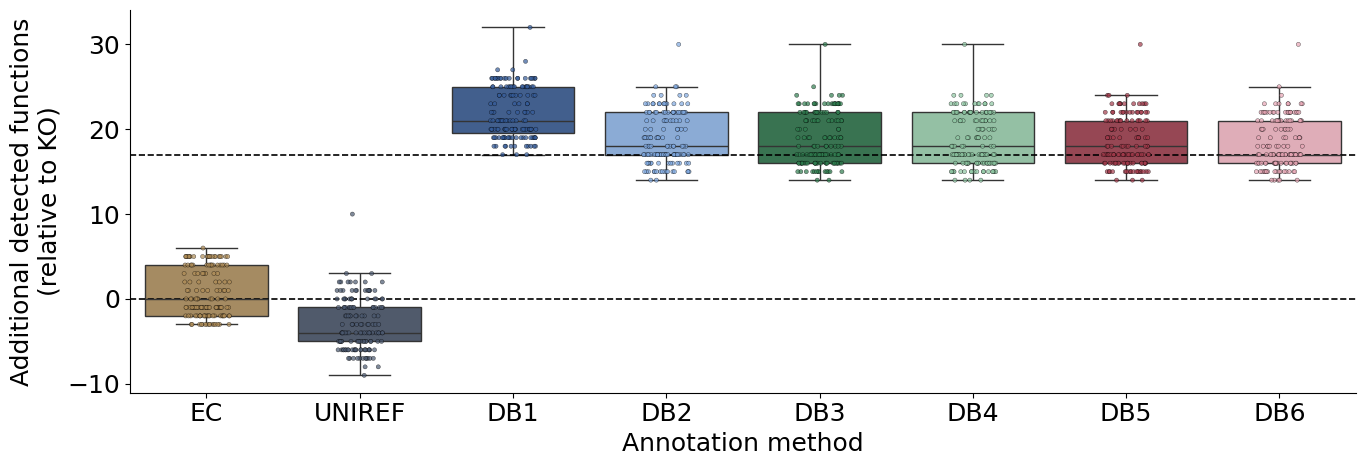

In [4]:
plt.rcParams.update({
    "font.size": 18,        # base size (applies to everything not set below)
    "axes.labelsize": 18,   # xlabel/ylabel
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
})

method_order = ["EC", "UNIREF", "DB1", "DB2", "DB3", "DB4", "DB5", "DB6"]

colors = [
    "#B08D57",  # EC
    "#4B5970",  # UNIREF

    "#355C9A",  # DB1
    "#7FA9E1",  # DB2

    "#2F7D4F",  # DB3
    "#8DC7A2",  # DB4

    "#A33A4B",  # DB5
    "#E7A5B4",  # DB6
]

plt.figure(figsize=(14, 5))

ax = sns.boxplot(
    data=gain_df,
    x="Method",
    y="Gain",
    order=method_order,
    hue="Method",
    palette=colors,
    dodge=False,
    showfliers=False,
    legend=False
)

sns.stripplot(
    data=gain_df,
    x="Method",
    y="Gain",
    order=method_order,
    hue="Method",
    palette=colors,
    dodge=False,
    jitter=0.15,
    size=3,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.3,
    legend=False
)

# No gain relative to KO
ax.axhline(y=0, color="black", linestyle="--", linewidth=1.2)

ax.axhline(y=17, color="black", linestyle="--", linewidth=1.2)

plt.xlabel("Annotation method")
plt.ylabel("Additional detected functions\n(relative to KO)")

sns.despine()
plt.tight_layout()
plt.savefig("gain_boxplot_all_methods.png", dpi=300)
plt.show()

## 2. Detection per function

For each method, counts the number of samples in which each function was detected (relab > 0 for KO, counts > 0 for the DIAMOND-based methods). Gene names are converted to upper case, and lic3A/lic3B are merged into LIC3X and cpsK into LST.

In [6]:
gene_merge = {"LIC3A": "LIC3X", "LIC3B": "LIC3X", "CPSK": "LST"}

def load(path, value_col):
    """Read a long-format table and keep only rows where the function was detected."""
    d = pd.read_csv(path, sep="\t")
    d.columns = d.columns.str.strip().str.lower()
    d["function"] = d["function"].astype(str).str.strip().str.upper().replace(gene_merge)
    d["sample"] = d["sample"].str.replace("_merged", "", regex=False)
    return d[d[value_col] > 0]

def n_samples(d, name):
    """Number of samples in which each function was detected."""
    return d.groupby("function")["sample"].nunique().rename(name)

ko = load("/media/Kirk/thais/SialoCat/humann_outputs/humann_outputs_uniref/ko_relab_all_samples.tsv", "relab")
counts = [n_samples(ko, "KO_detected")]

for m in ["UNIREF", "DB1", "DB2", "DB3", "DB4", "DB5", "DB6"]:
    d = load(f"/media/Kirk/thais/SialoCat/DBs_HITS_summary/{m}_HITS_summary_scov.tsv", "counts")
    counts.append(n_samples(d, f"{m}_detected"))

function_per_sample = pd.concat(counts, axis=1).fillna(0).astype(int).reset_index()
function_per_sample.to_csv("function_per_sample.tsv", sep="\t", index=False)

In [7]:
plt.rcdefaults()

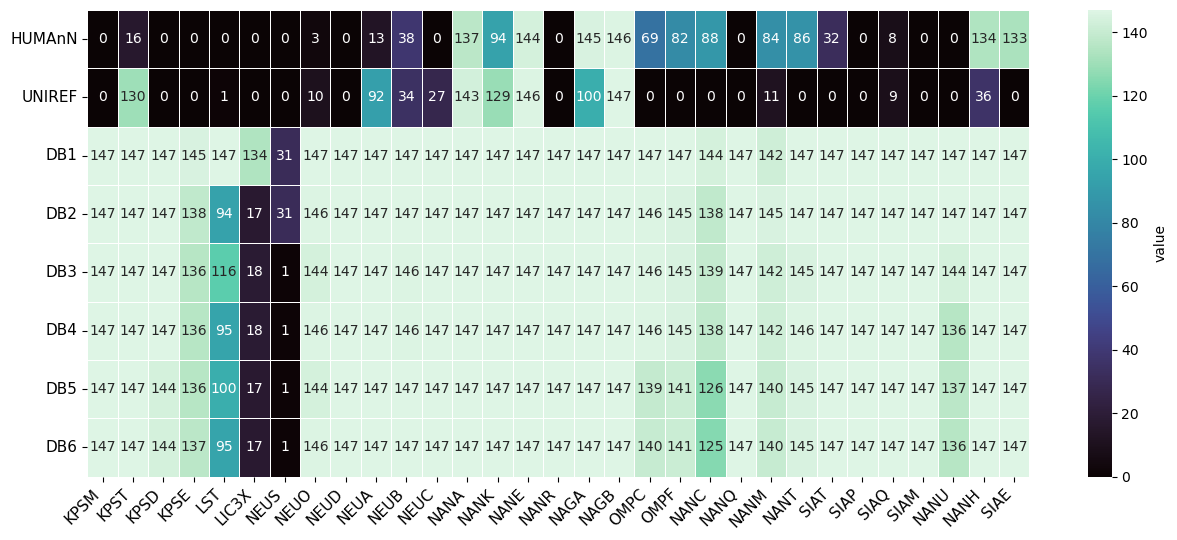

In [8]:
df = pd.read_csv("function_per_sample.tsv", sep="\t")

gene_order = [
    "KPSM", "KPST", "KPSD",
    "KPSE", "LST", "LIC3X",
    "NEUE", "NEUS", "NEUO", "NEUD",
    "NEUA", "NEUB", "NEUC", "NANA",
    "NANK", "NANE", "NANR", "NAGA",
    "NAGB", "OMPC", "OMPF", "NANC",
    "NANQ", "NANM", "NANT", "SIAT",
    "SIAP", "SIAQ", "SIAM", "NANU",
    "NANH", "SIAE"
]

df = df[df["function"].isin(gene_order)].copy()

df["function"] = pd.Categorical(df["function"], categories=gene_order, ordered=True)

df = df.sort_values("function").reset_index(drop=True)

methods = [
    "KO_detected", "UNIREF_detected",
    "DB1_detected", "DB2_detected", "DB3_detected",
    "DB4_detected", "DB5_detected", "DB6_detected"
]

method_labels = ["HUMAnN", "UNIREF", "DB1", "DB2", "DB3", "DB4", "DB5", "DB6"]

# --- method x gene matrix ---
heatmap_data = df.set_index("function")[methods]
heatmap_data.columns = method_labels

heatmap_data_T = heatmap_data.T

fig, ax = plt.subplots(figsize=(0.35 * len(heatmap_data_T.columns) + 2, 0.5 * len(heatmap_data_T) + 1.5))

sns.heatmap(
    heatmap_data_T,
    cmap="mako",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "value"},
    ax=ax
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=11)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=11)

plt.tight_layout()
plt.savefig("heatmap_all_methods.png", dpi=300)
plt.show()